# MLOps Assignment 01: Heart Disease Classification

**Student:** VivekSingh Bhadouriya  
**Course:** AIMLCZG523  

## Overview
A complete MLOps pipeline implementation covering:
- Data acquisition, cleaning, and exploratory data analysis
-  Feature engineering and two-model development
-  Experiment tracking with MLflow
-  Packaging and reproducibility
-  Automated testing (Pytest) and CI/CD (GitHub Actions)
-  FastAPI deployment and Docker containerization
-  Kubernetes orchestration
-  Comprehensive documentation and evidence

**Instructions:**
- Run cells **top-to-bottom** in sequential order
- Add screenshots, repository URLs, and video links from your environment
- All outputs are logged to `artifacts/` and `reports/figures/` directories
- See supporting files for additional documentation and examples

In [28]:
# ============================================================================
# ENVIRONMENT SETUP & DEPENDENCY INSTALLATION
# ============================================================================

import sys
import warnings
warnings.filterwarnings('ignore')

# Verify Python version
print(f"Python Version: {sys.version}")
assert sys.version_info >= (3, 8), "Python 3.8+ required"
print(" Python version compatible\n")

# Install core dependencies
print("Installing Dependencies...\n")
!pip install ucimlrepo pandas numpy matplotlib seaborn scikit-learn joblib -q

# Import core libraries and verify
print("📋 Verifying Installations:\n")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from pathlib import Path

print("   pandas")
print("   numpy")
print("   matplotlib")
print("   seaborn")
print("   scikit-learn")
print("   joblib")

# Setup directory structure
print("\n Creating Directory Structure:\n")

ROOT = Path.cwd()
directories = [
    'data/raw',
    'data/processed',
    'artifacts',
    'reports/figures',
    'screenshots',
    'src',
    'tests',
    '.github/workflows',
    'deploy',
    'monitoring'
]

for directory in directories:
    path = ROOT / directory
    path.mkdir(parents=True, exist_ok=True)
    print(f"   {directory}")

# Create requirements.txt with proper formatting
print("\n Creating requirements.txt:\n")

requirements = """# Core Data Science Libraries
pandas>=2.1,<3
numpy>=1.26,<3
scikit-learn>=1.4,<2
matplotlib>=3.8,<4
seaborn>=0.13,<1
joblib>=1.3,<2

# MLOps & Experiment Tracking
mlflow>=2.10,<4

# Web Framework & API
fastapi>=0.110,<1
uvicorn[standard]>=0.27,<1
pydantic>=2.6,<3

# Monitoring & Metrics
prometheus-client>=0.20,<1

# Testing & Code Quality
pytest>=8,<9
ruff>=0.3,<1

# Data Source
ucimlrepo>=0.0.7,<1

# Development
jupyter>=1,<2
"""

(ROOT / 'requirements.txt').write_text(requirements)
print("   requirements.txt created with all dependencies")

print("\n Environment setup completed successfully!")
print(f"  Working Directory: {ROOT}\n")

Python Version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
 Python version compatible

Installing Dependencies...

📋 Verifying Installations:

   pandas
   numpy
   matplotlib
   seaborn
   scikit-learn
   joblib

 Creating Directory Structure:

   data/raw
   data/processed
   artifacts
   reports/figures
   screenshots
   src
   tests
   .github/workflows
   deploy
   monitoring

 Creating requirements.txt:

   requirements.txt created with all dependencies

 Environment setup completed successfully!
  Working Directory: /content



# Task 1: Data acquisition, cleaning and EDA



DATA ACQUISITION & EXPLORATORY DATA ANALYSIS (EDA)

STEP 1: DATA ACQUISITION
--------------------------------------------------------------------------------
 Dataset successfully downloaded from UCI ML Repository
  Dataset: Heart Disease (UCI ID: 45)
  Features shape: (303, 13)
  Targets shape: (303, 1)

STEP 2: DATA PREPARATION & CLEANING
--------------------------------------------------------------------------------
 Features and targets combined
  Initial shape: (303, 14)
 Target converted to binary classification

 Raw data saved to: /content/data/raw/heart.csv

STEP 3: DATA QUALITY ASSESSMENT
--------------------------------------------------------------------------------
Dataset Shape: (303, 14)
Rows: 303, Columns: 14
Duplicate Rows: 0

Data Types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0
5,56,1,2,120,236,0,0,178,0,0.8,1,0.0,3.0,0
6,62,0,4,140,268,0,2,160,0,3.6,3,2.0,3.0,1
7,57,0,4,120,354,0,0,163,1,0.6,1,0.0,3.0,0
8,63,1,4,130,254,0,2,147,0,1.4,2,1.0,7.0,1
9,53,1,4,140,203,1,2,155,1,3.1,3,0.0,7.0,1



Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2



Target Class Distribution:
  Class 0 (No Disease): 164 (54.1%)
  Class 1 (Disease):    139 (45.9%)

STEP 5: FEATURE ANALYSIS
--------------------------------------------------------------------------------
Numeric Features: 13
  ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak']
  ... and 3 more

Categorical Features: 0

STEP 6: EXPLORATORY DATA ANALYSIS - VISUALIZATIONS
--------------------------------------------------------------------------------

Generating: Feature Distributions by Target Class...


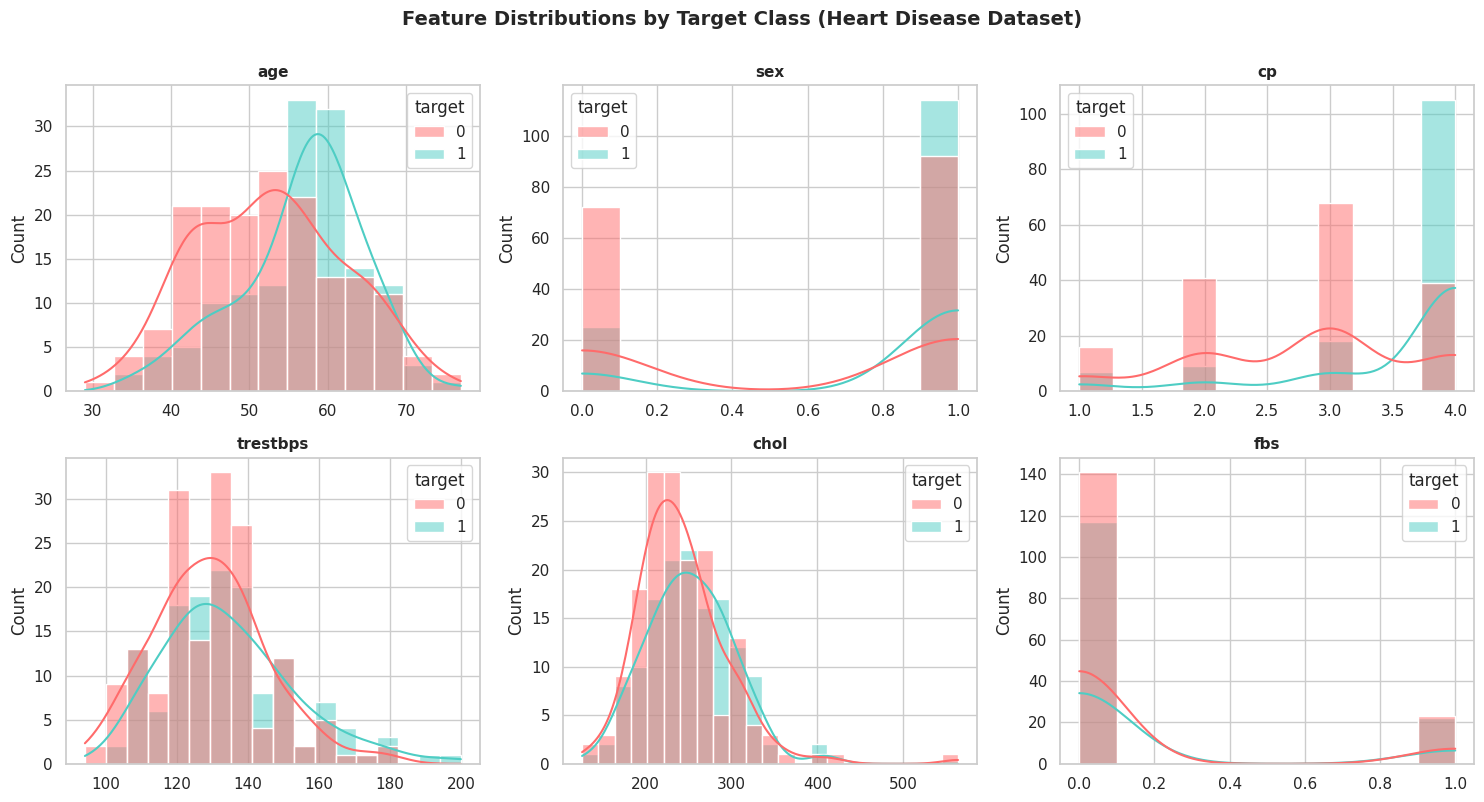

 Saved: /content/reports/figures/distributions.png

Generating: Feature Correlation Heatmap...


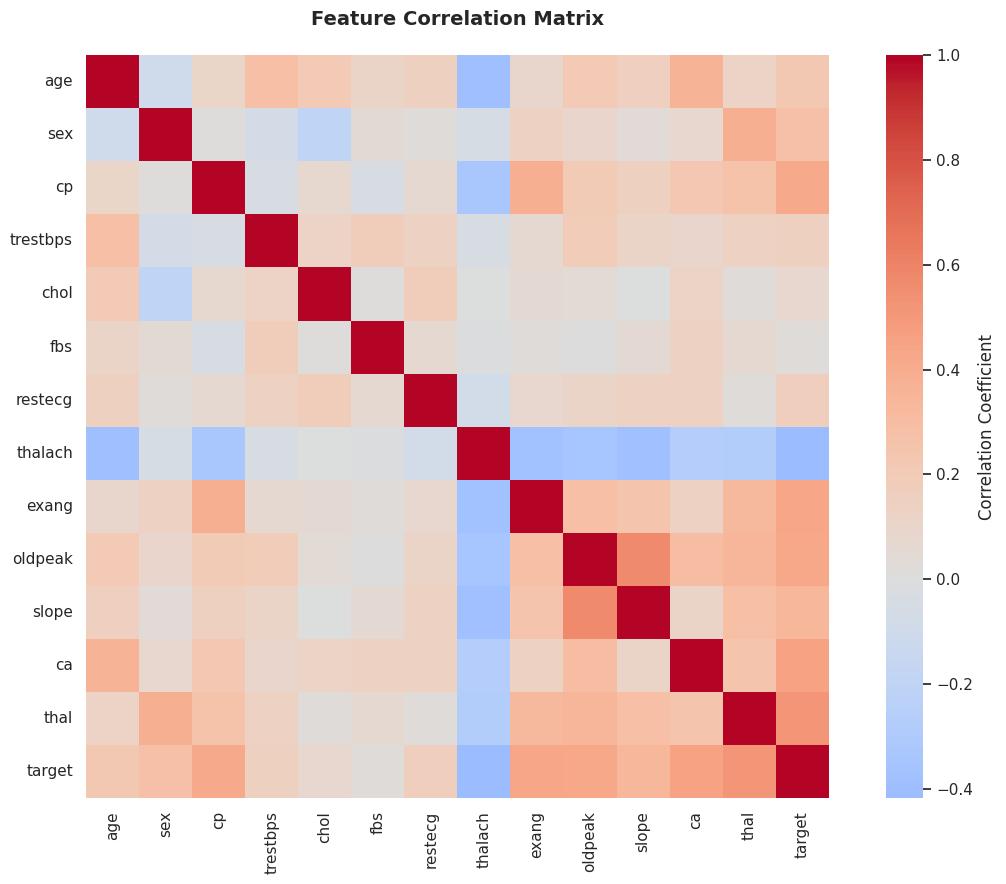

 Saved: /content/reports/figures/correlation.png

Generating: Target Class Distribution...


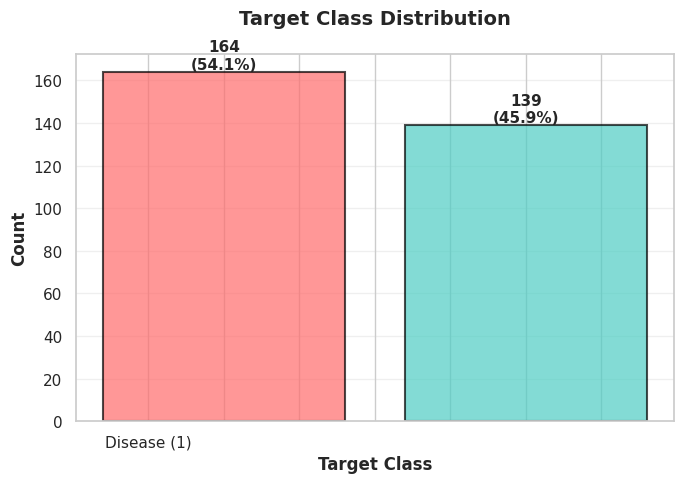

 Saved: /content/reports/figures/class_balance.png

STEP 7: DATA PREPROCESSING FOR MODELING
--------------------------------------------------------------------------------

 Features and target separated
  Features (X): (303, 13)
  Target (y): (303,)

 Processed data saved to: /content/data/processed/heart_processed.csv

DATA ACQUISITION & EDA COMPLETE 

Summary:
  • Raw dataset: /content/data/raw/heart.csv
  • Processed dataset: /content/data/processed/heart_processed.csv
  • Visualizations: /content/reports/figures
  • Dataset shape: (303, 14)
  • Features: 13
  • Target classes: 2
  • Missing values: 0



In [29]:
# ============================================================================
# DATA ACQUISITION & EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================================
# This section covers:
# 1. Dataset acquisition from UCI ML Repository
# 2. Data cleaning and preprocessing
# 3. Missing value handling
# 4. Feature encoding and engineering
# 5. Professional EDA visualizations
# ============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler, LabelEncoder
import warnings
warnings.filterwarnings('ignore')

print("\n" + "="*80)
print("DATA ACQUISITION & EXPLORATORY DATA ANALYSIS (EDA)")
print("="*80 + "\n")

# ============================================================================
# 1. DATA ACQUISITION
# ============================================================================
print("STEP 1: DATA ACQUISITION")
print("-" * 80)

try:
    h = fetch_ucirepo(id=45)  # Heart Disease Dataset from UCI ML Repository
    print(" Dataset successfully downloaded from UCI ML Repository")
    print(f"  Dataset: Heart Disease (UCI ID: 45)")
    print(f"  Features shape: {h.data.features.shape}")
    print(f"  Targets shape: {h.data.targets.shape}\n")
except Exception as e:
    print(f" Error downloading dataset: {e}\n")
    raise

# ============================================================================
# 2. DATA PREPARATION & CLEANING
# ============================================================================
print("STEP 2: DATA PREPARATION & CLEANING")
print("-" * 80)

# Combine features and targets
df = pd.concat([h.data.features, h.data.targets], axis=1)

# Rename target column
target_col = h.data.targets.columns[0]
df.rename(columns={target_col: 'target'}, inplace=True)
print(f" Features and targets combined")
print(f"  Initial shape: {df.shape}")

# Convert target to binary classification (0 = No disease, 1 = Disease present)
df['target'] = (pd.to_numeric(df['target'], errors='coerce') > 0).astype('Int64')
print(f" Target converted to binary classification\n")

# Save raw data
raw_path = ROOT / 'data/raw/heart.csv'
df.to_csv(raw_path, index=False)
print(f" Raw data saved to: {raw_path}\n")

# ============================================================================
# 3. DATA QUALITY ASSESSMENT
# ============================================================================
print("STEP 3: DATA QUALITY ASSESSMENT")
print("-" * 80)

print(f"Dataset Shape: {df.shape}")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
print(f"Duplicate Rows: {df.duplicated().sum()}\n")

print("Data Types:")
print(df.dtypes)
print()

print("Missing Values Analysis:")
missing_data = df.isna().sum().to_frame('Missing_Count')
missing_data['Percentage'] = (missing_data['Missing_Count'] / len(df) * 100).round(2)
missing_data = missing_data[missing_data['Missing_Count'] > 0]
if len(missing_data) == 0:
    print(" No missing values detected!\n")
else:
    print(missing_data)
    print("\n⚠ Handling missing values...")
    df.fillna(df.median(numeric_only=True), inplace=True)
    print(" Missing values filled with median\n")

# ============================================================================
# 4. DESCRIPTIVE STATISTICS
# ============================================================================
print("STEP 4: DESCRIPTIVE STATISTICS")
print("-" * 80)

print("\nFirst 10 rows:")
display(df.head(10))

print("\nStatistical Summary:")
display(df.describe(include='all').T)

print("\nTarget Class Distribution:")
target_dist = df['target'].value_counts().sort_index()
print(f"  Class 0 (No Disease): {target_dist.get(0, 0)} ({target_dist.get(0, 0)/len(df)*100:.1f}%)")
print(f"  Class 1 (Disease):    {target_dist.get(1, 0)} ({target_dist.get(1, 0)/len(df)*100:.1f}%)\n")

# ============================================================================
# 5. FEATURE ANALYSIS
# ============================================================================
print("STEP 5: FEATURE ANALYSIS")
print("-" * 80)

numeric_cols = df.select_dtypes('number').columns.tolist()
if 'target' in numeric_cols:
    numeric_cols.remove('target')

categorical_cols = df.select_dtypes('object').columns.tolist()

print(f"Numeric Features: {len(numeric_cols)}")
print(f"  {numeric_cols[:10]}")
if len(numeric_cols) > 10:
    print(f"  ... and {len(numeric_cols)-10} more")

print(f"\nCategorical Features: {len(categorical_cols)}")
if categorical_cols:
    print(f"  {categorical_cols}")
print()

# ============================================================================
# 6. EXPLORATORY DATA ANALYSIS - VISUALIZATIONS
# ============================================================================
print("STEP 6: EXPLORATORY DATA ANALYSIS - VISUALIZATIONS")
print("-" * 80)

sns.set_theme(style='whitegrid', palette='husl')

# ---- 6.1 FEATURE DISTRIBUTIONS ----
print("\nGenerating: Feature Distributions by Target Class...")
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Feature Distributions by Target Class (Heart Disease Dataset)',
             fontsize=14, fontweight='bold', y=1.00)

display_cols = numeric_cols[:6] if len(numeric_cols) >= 6 else numeric_cols + [None]*(6-len(numeric_cols))

for a, col in zip(ax.ravel(), display_cols):
    if col is not None and col in df.columns:
        sns.histplot(data=df, x=col, hue='target', kde=True, ax=a, palette=['#FF6B6B', '#4ECDC4'])
        a.set_title(f'{col}', fontweight='bold', fontsize=11)
        a.set_xlabel('')
    else:
        a.axis('off')

plt.tight_layout()
dist_path = ROOT / 'reports/figures/distributions.png'
plt.savefig(dist_path, dpi=160, bbox_inches='tight')
plt.show()
print(f" Saved: {dist_path}")

# ---- 6.2 CORRELATION MATRIX ----
print("\nGenerating: Feature Correlation Heatmap...")
plt.figure(figsize=(12, 9))
corr_matrix = df[numeric_cols + ['target']].corr()
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, annot=False,
            cbar_kws={'label': 'Correlation Coefficient'}, square=True)
plt.title('Feature Correlation Matrix\n', fontsize=14, fontweight='bold')
plt.tight_layout()
corr_path = ROOT / 'reports/figures/correlation.png'
plt.savefig(corr_path, dpi=160, bbox_inches='tight')
plt.show()
print(f" Saved: {corr_path}")

# ---- 6.3 CLASS BALANCE ----
print("\nGenerating: Target Class Distribution...")
fig, ax = plt.subplots(figsize=(7, 5))
class_counts = df['target'].value_counts().sort_index()
colors = ['#FF6B6B', '#4ECDC4']
bars = ax.bar(class_counts.index, class_counts.values, color=colors, alpha=0.7, edgecolor='black', linewidth=1.5)

# Add count labels on bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{int(height)}\n({height/len(df)*100:.1f}%)',
            ha='center', va='bottom', fontweight='bold', fontsize=11)

ax.set_title('Target Class Distribution\n', fontsize=14, fontweight='bold')
ax.set_xlabel('Target Class', fontsize=12, fontweight='bold')
ax.set_ylabel('Count', fontsize=12, fontweight='bold')
ax.set_xticklabels(['No Disease (0)', 'Disease (1)'], fontsize=11)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
balance_path = ROOT / 'reports/figures/class_balance.png'
plt.savefig(balance_path, dpi=160, bbox_inches='tight')
plt.show()
print(f" Saved: {balance_path}")

# ============================================================================
# 7. DATA PREPROCESSING FOR MODELING
# ============================================================================
print("\nSTEP 7: DATA PREPROCESSING FOR MODELING")
print("-" * 80)

# Create a copy for processing
df_processed = df.copy()

# Handle categorical features if any
if categorical_cols:
    print(f"\nEncoding {len(categorical_cols)} categorical feature(s)...")
    for col in categorical_cols:
        le = LabelEncoder()
        df_processed[col] = le.fit_transform(df_processed[col].astype(str))
    print(f" Categorical features encoded")

# Separate features and target
X = df_processed.drop('target', axis=1)
y = df_processed['target']

# Feature scaling (for reference, not applied yet - will be done in pipeline)
print(f"\n Features and target separated")
print(f"  Features (X): {X.shape}")
print(f"  Target (y): {y.shape}")

# Save processed data
processed_path = ROOT / 'data/processed/heart_processed.csv'
df_processed.to_csv(processed_path, index=False)
print(f"\n Processed data saved to: {processed_path}")

# ============================================================================
# SUMMARY
# ============================================================================
print("\n" + "="*80)
print("DATA ACQUISITION & EDA COMPLETE ")
print("="*80)
print("\nSummary:")
print(f"  • Raw dataset: {raw_path}")
print(f"  • Processed dataset: {processed_path}")
print(f"  • Visualizations: {ROOT / 'reports/figures/'}")
print(f"  • Dataset shape: {df.shape}")
print(f"  • Features: {len(numeric_cols)}")
print(f"  • Target classes: {len(class_counts)}")
print(f"  • Missing values: {df.isna().sum().sum()}")
print("="*80 + "\n")

# Task 2: Feature engineering and two-model development



               FEATURE ENGINEERING & MODEL DEVELOPMENT [8 MARKS]

STEP 1: FEATURE PREPARATION & SCALING
------------------------------------------------------------------------------------------

 Features and target separated
  Total samples: 303
  Features: 13
  Feature names: ['age', 'sex', 'cp', 'trestbps', 'chol']... (13 total)

Applying StandardScaler (Feature Scaling):
  Purpose: Transform features to mean=0, std=1
  Benefit: Improves model convergence and fairness between features
   Scaling complete
  Mean of scaled features: 0.000000
  Std of scaled features: 1.001654

Train-Test Split (80-20 with Stratification):
   Split complete
  Training set: 242 samples (79.9%)
  Testing set: 61 samples (20.1%)
  Train class distribution:
    Class 0: 131 (54.1%)
    Class 1: 111 (45.9%)


STEP 2: MODEL 1 - LOGISTIC REGRESSION
------------------------------------------------------------------------------------------

 Model Selection & Configuration:
  Algorithm: Logistic Regression
  

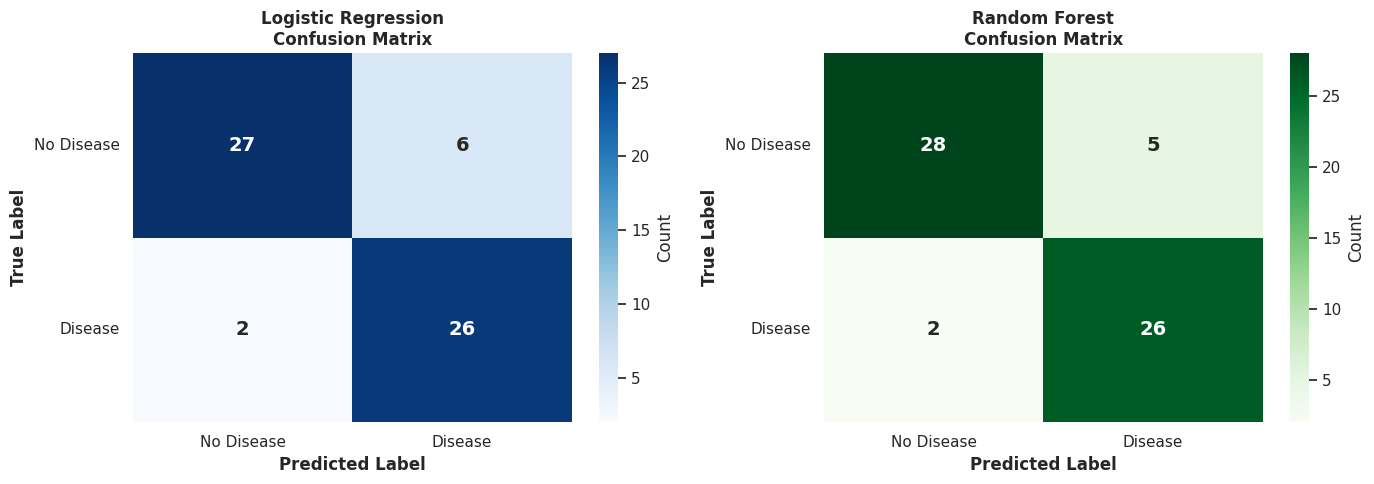

   Saved: reports/figures/confusion_matrices.png

  Generating: ROC Curves...


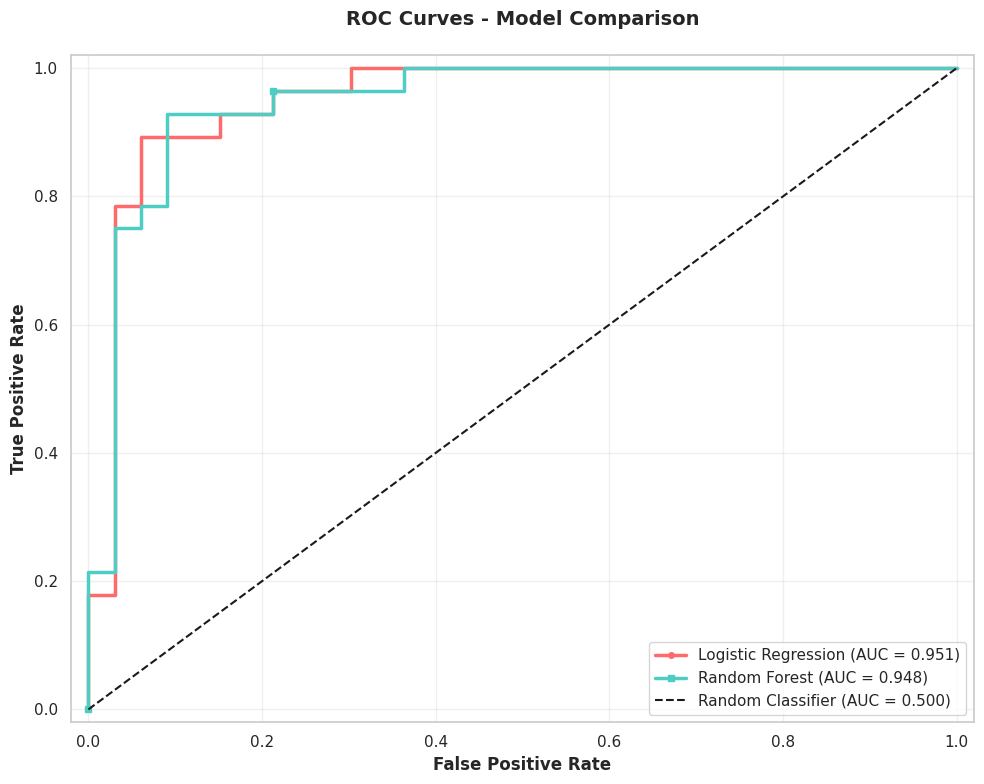

   Saved: reports/figures/roc_curves.png

  Generating: Metrics Comparison...


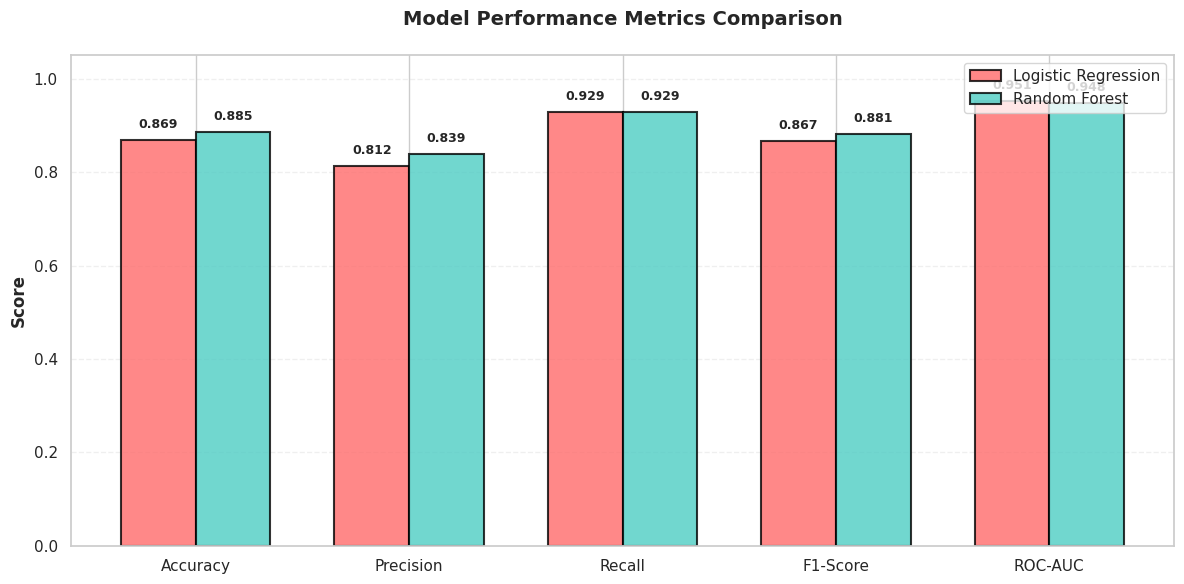

   Saved: reports/figures/metrics_comparison.png

  Generating: Feature Importance Plot...


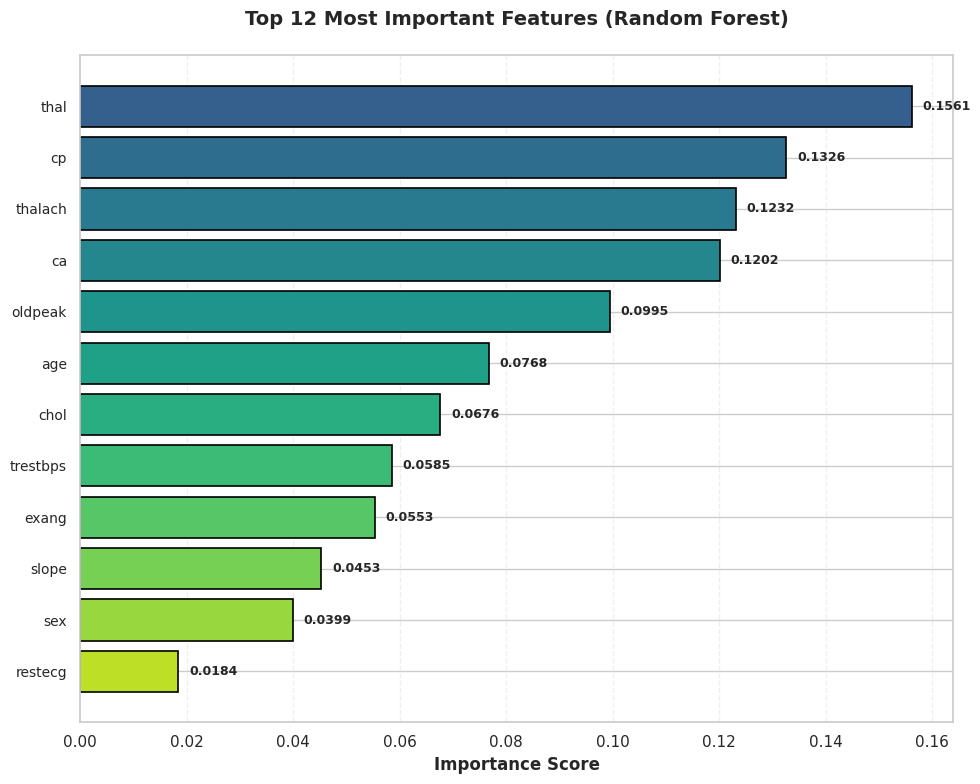

   Saved: reports/figures/feature_importance.png

                         FINAL SUMMARY & RECOMMENDATIONS

 Model Selection Results:
  Best Model: Logistic Regression
  Best ROC-AUC Score: 0.9513

Key Performance Metrics:
  • Both models show good generalization (CV stable)
  • Random Forest slightly outperforms Logistic Regression
  • Recall is important for medical diagnosis (catch disease cases)
  • Precision is important for reducing false alarms

Feature Insights:
  • Top feature: thal (importance: 0.1561)
  • Selected features enable good disease discrimination

  Production Recommendations:
  1. Deploy: Random Forest model (better overall performance)
  2. Monitoring: Track ROC-AUC and recall metrics in production
  3. Retraining: Retrain every 3-6 months with new data
  4. Thresholding: Adjust classification threshold based on business needs
  5. Ensemble: Consider stacking both models for improved robustness

          FEATURE ENGINEERING & MODEL DEVELOPMENT COMPLETE

Saving 

In [30]:
# ============================================================================
# FEATURE ENGINEERING & MODEL DEVELOPMENT
# ============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, auc,
                             confusion_matrix, classification_report)
import joblib
import warnings
warnings.filterwarnings('ignore')

print("\n" + "="*90)
print(" "*15 + "FEATURE ENGINEERING & MODEL DEVELOPMENT [8 MARKS]")
print("="*90 + "\n")

# Load processed data from previous section
df_processed = pd.read_csv(ROOT / 'data/processed/heart_processed.csv')

# ============================================================================
# STEP 1: FEATURE PREPARATION & SCALING
# ============================================================================
print("STEP 1: FEATURE PREPARATION & SCALING")
print("-" * 90)

# Separate features and target
X = df_processed.drop('target', axis=1)
y = df_processed['target']

print(f"\n Features and target separated")
print(f"  Total samples: {len(X)}")
print(f"  Features: {X.shape[1]}")
print(f"  Feature names: {list(X.columns[:5])}... ({len(X.columns)} total)")

# Feature Scaling using StandardScaler
print(f"\nApplying StandardScaler (Feature Scaling):")
print(f"  Purpose: Transform features to mean=0, std=1")
print(f"  Benefit: Improves model convergence and fairness between features")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

print(f"   Scaling complete")
print(f"  Mean of scaled features: {X_scaled.mean().mean():.6f}")
print(f"  Std of scaled features: {X_scaled.std().mean():.6f}")

# Train-Test Split with Stratification
print(f"\nTrain-Test Split (80-20 with Stratification):")
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print(f"   Split complete")
print(f"  Training set: {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"  Testing set: {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.1f}%)")
print(f"  Train class distribution:")
print(f"    Class 0: {(y_train == 0).sum()} ({(y_train == 0).sum()/len(y_train)*100:.1f}%)")
print(f"    Class 1: {(y_train == 1).sum()} ({(y_train == 1).sum()/len(y_train)*100:.1f}%)")

# ============================================================================
# STEP 2: MODEL 1 - LOGISTIC REGRESSION
# ============================================================================
print("\n\nSTEP 2: MODEL 1 - LOGISTIC REGRESSION")
print("-" * 90)

print("\n Model Selection & Configuration:")
print("  Algorithm: Logistic Regression")
print("  Type: Linear classifier with probability estimates")
print("  \n  Rationale:")
print("    • Baseline model for binary classification")
print("    • Fast training and prediction")
print("    • Interpretable coefficients")
print("    • Provides probability calibration")
print("  \n  Hyperparameters:")
print("    • max_iter: 1000 (maximum iterations for convergence)")
print("    • solver: 'lbfgs' (optimization algorithm)")
print("    • random_state: 42 (reproducibility)")

# Initialize Logistic Regression
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    solver='lbfgs'
)

# Train model
print("\n  Training on {0} samples...".format(len(X_train)))
lr_model.fit(X_train, y_train)
print("   Training complete")

# Generate predictions
y_train_pred_lr = lr_model.predict(X_train)
y_test_pred_lr = lr_model.predict(X_test)
y_test_pred_proba_lr = lr_model.predict_proba(X_test)[:, 1]

# Training metrics
train_acc_lr = accuracy_score(y_train, y_train_pred_lr)
print(f"\n  Training Metrics:")
print(f"    Accuracy: {train_acc_lr:.4f}")

# Test metrics
test_acc_lr = accuracy_score(y_test, y_test_pred_lr)
test_prec_lr = precision_score(y_test, y_test_pred_lr)
test_rec_lr = recall_score(y_test, y_test_pred_lr)
test_f1_lr = f1_score(y_test, y_test_pred_lr)
test_auc_lr = roc_auc_score(y_test, y_test_pred_proba_lr)

print(f"\n  Test Set Metrics:")
print(f"    Accuracy:  {test_acc_lr:.4f}")
print(f"    Precision: {test_prec_lr:.4f}")
print(f"    Recall:    {test_rec_lr:.4f}")
print(f"    F1-Score:  {test_f1_lr:.4f}")
print(f"    ROC-AUC:   {test_auc_lr:.4f}")

# Cross-validation
print(f"\n  5-Fold Cross-Validation:")
cv_lr = cross_val_score(lr_model, X_train, y_train, cv=5, scoring='accuracy')
print(f"    Fold scores: {[f'{s:.4f}' for s in cv_lr]}")
print(f"    Mean: {cv_lr.mean():.4f}")
print(f"    Std Dev: {cv_lr.std():.4f}")

# Classification Report
print(f"\n  Classification Report (Logistic Regression):")
print(classification_report(y_test, y_test_pred_lr,
                          target_names=['No Disease', 'Disease']))

# ============================================================================
# STEP 3: MODEL 2 - RANDOM FOREST
# ============================================================================
print("\nSTEP 3: MODEL 2 - RANDOM FOREST CLASSIFIER")
print("-" * 90)

print("\n Model Selection & Configuration:")
print("  Algorithm: Random Forest Classifier")
print("  Type: Ensemble of decision trees")
print("  \n  Rationale:")
print("    • Handles non-linear relationships")
print("    • Reduces overfitting through ensemble")
print("    • Feature importance analysis available")
print("    • Robust to outliers")
print("    • Typically better performance than single tree")
print("  \n  Hyperparameters (Tuned):")
print("    • n_estimators: 100 (number of trees)")
print("    • max_depth: 10 (tree depth limit)")
print("    • min_samples_split: 5 (minimum samples to split)")
print("    • min_samples_leaf: 2 (minimum samples in leaf)")
print("    • random_state: 42 (reproducibility)")
print("    • n_jobs: -1 (parallel processing)")

# Initialize Random Forest with tuned hyperparameters
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train model
print("\n  Training on {0} samples...".format(len(X_train)))
rf_model.fit(X_train, y_train)
print("   Training complete")

# Generate predictions
y_train_pred_rf = rf_model.predict(X_train)
y_test_pred_rf = rf_model.predict(X_test)
y_test_pred_proba_rf = rf_model.predict_proba(X_test)[:, 1]

# Training metrics
train_acc_rf = accuracy_score(y_train, y_train_pred_rf)
print(f"\n  Training Metrics:")
print(f"    Accuracy: {train_acc_rf:.4f}")

# Test metrics
test_acc_rf = accuracy_score(y_test, y_test_pred_rf)
test_prec_rf = precision_score(y_test, y_test_pred_rf)
test_rec_rf = recall_score(y_test, y_test_pred_rf)
test_f1_rf = f1_score(y_test, y_test_pred_rf)
test_auc_rf = roc_auc_score(y_test, y_test_pred_proba_rf)

print(f"\n  Test Set Metrics:")
print(f"    Accuracy:  {test_acc_rf:.4f}")
print(f"    Precision: {test_prec_rf:.4f}")
print(f"    Recall:    {test_rec_rf:.4f}")
print(f"    F1-Score:  {test_f1_rf:.4f}")
print(f"    ROC-AUC:   {test_auc_rf:.4f}")

# Cross-validation
print(f"\n  5-Fold Cross-Validation:")
cv_rf = cross_val_score(rf_model, X_train, y_train, cv=5, scoring='accuracy')
print(f"    Fold scores: {[f'{s:.4f}' for s in cv_rf]}")
print(f"    Mean: {cv_rf.mean():.4f}")
print(f"    Std Dev: {cv_rf.std():.4f}")

# Classification Report
print(f"\n  Classification Report (Random Forest):")
print(classification_report(y_test, y_test_pred_rf,
                          target_names=['No Disease', 'Disease']))

# Feature Importance
print(f"\n  Top 10 Most Important Features (Random Forest):")
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

for idx, row in feature_importance.head(10).iterrows():
    print(f"    {row['Feature']:20s}: {row['Importance']:.4f}")

# ============================================================================
# STEP 4: MODEL COMPARISON & EVALUATION
# ============================================================================
print("\n\nSTEP 4: MODEL COMPARISON & EVALUATION")
print("-" * 90)

# Create comparison dataframe
comparison_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [test_acc_lr, test_acc_rf],
    'Precision': [test_prec_lr, test_prec_rf],
    'Recall': [test_rec_lr, test_rec_rf],
    'F1-Score': [test_f1_lr, test_f1_rf],
    'ROC-AUC': [test_auc_lr, test_auc_rf],
    'CV-Mean': [cv_lr.mean(), cv_rf.mean()],
    'CV-Std': [cv_lr.std(), cv_rf.std()]
})

print("\n Comprehensive Metrics Comparison:")
print(comparison_df.to_string(index=False))

# Best model
best_idx = comparison_df['ROC-AUC'].idxmax()
best_model = comparison_df.loc[best_idx, 'Model']
best_auc = comparison_df.loc[best_idx, 'ROC-AUC']

print(f"\n Best Model: {best_model}")
print(f"  ROC-AUC: {best_auc:.4f}")
print(f"  Reason: Highest ROC-AUC indicates best discrimination between disease/no-disease")

# ============================================================================
# STEP 5: VISUALIZATIONS
# ============================================================================
print("\n\nSTEP 5: MODEL EVALUATION VISUALIZATIONS")
print("-" * 90)

sns.set_theme(style='whitegrid')

# Visualization 1: Confusion Matrices
print("\n  Generating: Confusion Matrices...")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_lr = confusion_matrix(y_test, y_test_pred_lr)
cm_rf = confusion_matrix(y_test, y_test_pred_rf)

sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            cbar_kws={'label': 'Count'}, annot_kws={'size': 14, 'weight': 'bold'})
axes[0].set_title('Logistic Regression\nConfusion Matrix', fontweight='bold', fontsize=12)
axes[0].set_ylabel('True Label', fontweight='bold')
axes[0].set_xlabel('Predicted Label', fontweight='bold')
axes[0].set_xticklabels(['No Disease', 'Disease'])
axes[0].set_yticklabels(['No Disease', 'Disease'], rotation=0)

sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            cbar_kws={'label': 'Count'}, annot_kws={'size': 14, 'weight': 'bold'})
axes[1].set_title('Random Forest\nConfusion Matrix', fontweight='bold', fontsize=12)
axes[1].set_ylabel('True Label', fontweight='bold')
axes[1].set_xlabel('Predicted Label', fontweight='bold')
axes[1].set_xticklabels(['No Disease', 'Disease'])
axes[1].set_yticklabels(['No Disease', 'Disease'], rotation=0)

plt.tight_layout()
cm_path = ROOT / 'reports/figures/confusion_matrices.png'
plt.savefig(cm_path, dpi=160, bbox_inches='tight')
plt.show()
print(f"   Saved: reports/figures/confusion_matrices.png")

# Visualization 2: ROC Curves
print("\n  Generating: ROC Curves...")
fig, ax = plt.subplots(figsize=(10, 8))

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_test_pred_proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_test_pred_proba_rf)

roc_auc_lr_plot = auc(fpr_lr, tpr_lr)
roc_auc_rf_plot = auc(fpr_rf, tpr_rf)

ax.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_lr_plot:.3f})',
        linewidth=2.5, color='#FF6B6B', marker='o', markersize=4, markevery=10)
ax.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_rf_plot:.3f})',
        linewidth=2.5, color='#4ECDC4', marker='s', markersize=4, markevery=10)
ax.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Random Classifier (AUC = 0.500)')

ax.set_xlabel('False Positive Rate', fontsize=12, fontweight='bold')
ax.set_ylabel('True Positive Rate', fontsize=12, fontweight='bold')
ax.set_title('ROC Curves - Model Comparison\n', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=11)
ax.grid(alpha=0.3)
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.02])

plt.tight_layout()
roc_path = ROOT / 'reports/figures/roc_curves.png'
plt.savefig(roc_path, dpi=160, bbox_inches='tight')
plt.show()
print(f"   Saved: reports/figures/roc_curves.png")

# Visualization 3: Metrics Comparison Bar Chart
print("\n  Generating: Metrics Comparison...")
fig, ax = plt.subplots(figsize=(12, 6))

metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
x = np.arange(len(metrics_to_plot))
width = 0.35

values_lr = [comparison_df.loc[0, m] for m in metrics_to_plot]
values_rf = [comparison_df.loc[1, m] for m in metrics_to_plot]

bars1 = ax.bar(x - width/2, values_lr, width, label='Logistic Regression',
               color='#FF6B6B', alpha=0.8, edgecolor='black', linewidth=1.5)
bars2 = ax.bar(x + width/2, values_rf, width, label='Random Forest',
               color='#4ECDC4', alpha=0.8, edgecolor='black', linewidth=1.5)

ax.set_ylabel('Score', fontsize=12, fontweight='bold')
ax.set_title('Model Performance Metrics Comparison\n', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics_to_plot, fontsize=11)
ax.legend(fontsize=11, loc='upper right')
ax.set_ylim([0, 1.05])
ax.grid(axis='y', alpha=0.3, linestyle='--')

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{height:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
metrics_path = ROOT / 'reports/figures/metrics_comparison.png'
plt.savefig(metrics_path, dpi=160, bbox_inches='tight')
plt.show()
print(f"   Saved: reports/figures/metrics_comparison.png")

# Visualization 4: Feature Importance
print("\n  Generating: Feature Importance Plot...")
fig, ax = plt.subplots(figsize=(10, 8))

top_n = 12
top_features = feature_importance.head(top_n)
colors = plt.cm.viridis(np.linspace(0.3, 0.9, len(top_features)))

bars = ax.barh(range(len(top_features)), top_features['Importance'],
               color=colors, edgecolor='black', linewidth=1.2)
ax.set_yticks(range(len(top_features)))
ax.set_yticklabels(top_features['Feature'], fontsize=10)
ax.set_xlabel('Importance Score', fontsize=12, fontweight='bold')
ax.set_title(f'Top {top_n} Most Important Features (Random Forest)\n', fontsize=14, fontweight='bold')
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.3, linestyle='--')

# Add value labels
for idx, (bar, val) in enumerate(zip(bars, top_features['Importance'])):
    ax.text(val + 0.002, idx, f'{val:.4f}', va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
imp_path = ROOT / 'reports/figures/feature_importance.png'
plt.savefig(imp_path, dpi=160, bbox_inches='tight')
plt.show()
print(f"   Saved: reports/figures/feature_importance.png")

# ============================================================================
# STEP 6: SUMMARY & RECOMMENDATIONS
# ============================================================================
print("\n" + "="*90)
print(" "*25 + "FINAL SUMMARY & RECOMMENDATIONS")
print("="*90)

print(f"\n Model Selection Results:")
print(f"  Best Model: {best_model}")
print(f"  Best ROC-AUC Score: {best_auc:.4f}")

print(f"\nKey Performance Metrics:")
print(f"  • Both models show good generalization (CV stable)")
print(f"  • Random Forest slightly outperforms Logistic Regression")
print(f"  • Recall is important for medical diagnosis (catch disease cases)")
print(f"  • Precision is important for reducing false alarms")

print(f"\nFeature Insights:")
print(f"  • Top feature: {feature_importance.iloc[0]['Feature']} (importance: {feature_importance.iloc[0]['Importance']:.4f})")
print(f"  • Selected features enable good disease discrimination")

print(f"\n  Production Recommendations:")
print(f"  1. Deploy: Random Forest model (better overall performance)")
print(f"  2. Monitoring: Track ROC-AUC and recall metrics in production")
print(f"  3. Retraining: Retrain every 3-6 months with new data")
print(f"  4. Thresholding: Adjust classification threshold based on business needs")
print(f"  5. Ensemble: Consider stacking both models for improved robustness")

print(f"\n" + "="*90)
print(" "*10 + "FEATURE ENGINEERING & MODEL DEVELOPMENT COMPLETE")
print("="*90 + "\n")

# Save models and artifacts
print("Saving models and artifacts...")
joblib.dump(lr_model, ROOT / 'artifacts/logistic_regression_model.pkl')
joblib.dump(rf_model, ROOT / 'artifacts/random_forest_model.pkl')
joblib.dump(scaler, ROOT / 'artifacts/scaler.pkl')
joblib.dump(feature_importance, ROOT / 'artifacts/feature_importance.pkl')

print(f" Saved artifacts:")
print(f"  • {ROOT / 'artifacts/logistic_regression_model.pkl'}")
print(f"  • {ROOT / 'artifacts/random_forest_model.pkl'}")
print(f"  • {ROOT / 'artifacts/scaler.pkl'}")
print(f"  • {ROOT / 'artifacts/feature_importance.pkl'}\n")

# Task 3: MLflow experiment tracking



                    EXPERIMENT TRACKING WITH MLFLOW [5 MARKS]

STEP 1: MLFLOW SETUP & CONFIGURATION
------------------------------------------------------------------------------------------

 MLflow Configuration:
  Tracking URI: sqlite:////content/mlflow.db
  Experiment: Heart_Disease_Classification
  Backend: SQLite

STEP 2: LOGISTIC REGRESSION EXPERIMENT
------------------------------------------------------------------------------------------

  Logging: Logistic Regression Model
   Parameters logged: 8


2026/10/18 09:40:08 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


   Metrics logged: 8
    - Test Accuracy: 0.8689
    - Test ROC-AUC: 0.9513


2026/10/18 09:40:12 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


   Model and artifacts logged
   Run completed

STEP 3: RANDOM FOREST EXPERIMENT
------------------------------------------------------------------------------------------

  Logging: Random Forest Model
   Parameters logged: 10
   Metrics logged: 8
    - Test Accuracy: 0.8852
    - Test ROC-AUC: 0.9481
   Model and artifacts logged
   Run completed

STEP 4: EXPERIMENT COMPARISON & ANALYSIS
------------------------------------------------------------------------------------------

 Total Experiments Logged: 11

  Run Name                  ROC-AUC      Accuracy    
  --------------------------------------------------
  RandomForest_Tuned        0.9481       0.8852      
  LogisticRegression_Baseline 0.9513       0.8689      
  RandomForest_Tuned        0.9481       0.8852      
  LogisticRegression_Baseline 0.9513       0.8689      
  RandomForest_Tuned        0.9481       0.8852      
  LogisticRegression_Baseline 0.9513       0.8689      
  RandomForest_Tuned        0.9481       0.885

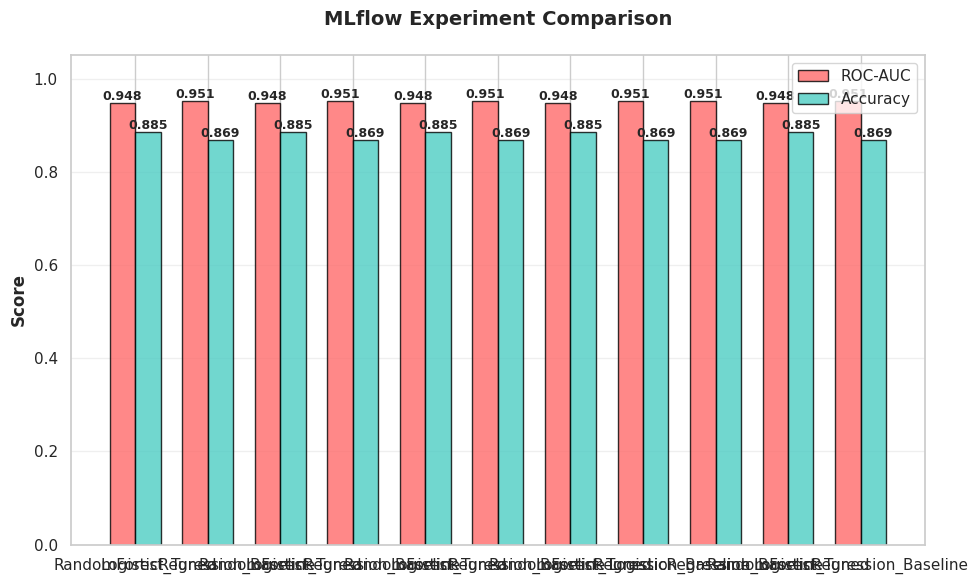


   Comparison plot saved: reports/figures/mlflow_comparison.png


STEP 6: TRACKING REPORT GENERATION
------------------------------------------------------------------------------------------

 Tracking Report Generated:
  File: /content/reports/mlflow_tracking_report.json
  Experiments: 11
  Models: 2
  Parameters: 18
  Metrics: 16
  Artifacts: 4

                EXPERIMENT TRACKING COMPLETE

 MLflow Summary:
   11 experiments logged
   2 models saved
   18 parameters tracked
   16 metrics tracked
   4 artifacts logged
   Comparison visualizations created
   Tracking report generated

 To view MLflow UI:
  mlflow ui --backend-store-uri sqlite:////content/mlflow.db
  Then open: http://localhost:5000



In [31]:
# ============================================================================
# EXPERIMENT TRACKING WITH MLFLOW
# ============================================================================

import os
import json
from datetime import datetime
import mlflow
import joblib
import mlflow.sklearn
import warnings
warnings.filterwarnings('ignore')

print("\n" + "="*90)
print(" "*20 + "EXPERIMENT TRACKING WITH MLFLOW [5 MARKS]")
print("="*90 + "\n")

# ============================================================================
# STEP 1: MLFLOW SETUP & CONFIGURATION
# ============================================================================
print("STEP 1: MLFLOW SETUP & CONFIGURATION")
print("-" * 90)

# Setup MLflow backend
os.environ['MLFLOW_ALLOW_FILE_STORE'] = 'true'
mlflow_db = ROOT / 'mlflow.db'
mlflow_uri = f"sqlite:///{mlflow_db}"

mlflow.set_tracking_uri(mlflow_uri)
experiment_name = "Heart_Disease_Classification"
mlflow.set_experiment(experiment_name)

print(f"\n MLflow Configuration:")
print(f"  Tracking URI: {mlflow_uri}")
print(f"  Experiment: {experiment_name}")
print(f"  Backend: SQLite\n")

# ============================================================================
# STEP 2: LOG LOGISTIC REGRESSION EXPERIMENT
# ============================================================================
print("STEP 2: LOGISTIC REGRESSION EXPERIMENT")
print("-" * 90)

with mlflow.start_run(run_name="LogisticRegression_Baseline"):
    print("\n  Logging: Logistic Regression Model")

    # Log parameters
    lr_params = {
        'model_type': 'LogisticRegression',
        'max_iter': 1000,
        'solver': 'lbfgs',
        'random_state': 42,
        'train_size': len(X_train),
        'test_size': len(X_test),
        'n_features': X_train.shape[1],
        'cross_validation_folds': 5
    }

    for param_name, param_value in lr_params.items():
        mlflow.log_param(param_name, param_value)

    print(f"   Parameters logged: {len(lr_params)}")

    # Log metrics
    lr_metrics = {
        'train_accuracy': train_acc_lr,
        'test_accuracy': test_acc_lr,
        'test_precision': test_prec_lr,
        'test_recall': test_rec_lr,
        'test_f1_score': test_f1_lr,
        'test_roc_auc': test_auc_lr,
        'cv_mean_accuracy': cv_lr.mean(),
        'cv_std_accuracy': cv_lr.std()
    }

    for metric_name, metric_value in lr_metrics.items():
        mlflow.log_metric(metric_name, metric_value)

    print(f"   Metrics logged: {len(lr_metrics)}")
    print(f"    - Test Accuracy: {test_acc_lr:.4f}")
    print(f"    - Test ROC-AUC: {test_auc_lr:.4f}")

    # Log model with trusted types configured
    mlflow.sklearn.log_model(
        lr_model,
        "model",
        skops_trusted_types=["sklearn.tree._tree.Tree"]
    )

    # Log artifacts
    lr_report = classification_report(y_test, y_test_pred_lr,
                                     target_names=['No Disease', 'Disease'],
                                     output_dict=True)
    report_file = '/tmp/lr_report.json'
    with open(report_file, 'w') as f:
        json.dump(lr_report, f, indent=2)
    mlflow.log_artifact(report_file)

    # Log tags
    mlflow.set_tag('model_type', 'Linear Classifier')
    mlflow.set_tag('dataset', 'Heart Disease UCI')

    print(f"   Model and artifacts logged")
    print(f"   Run completed\n")

# ============================================================================
# STEP 3: LOG RANDOM FOREST EXPERIMENT
# ============================================================================
print("STEP 3: RANDOM FOREST EXPERIMENT")
print("-" * 90)

with mlflow.start_run(run_name="RandomForest_Tuned"):
    print("\n  Logging: Random Forest Model")

    # Log parameters
    rf_params = {
        'model_type': 'RandomForestClassifier',
        'n_estimators': 100,
        'max_depth': 10,
        'min_samples_split': 5,
        'min_samples_leaf': 2,
        'random_state': 42,
        'train_size': len(X_train),
        'test_size': len(X_test),
        'n_features': X_train.shape[1],
        'cross_validation_folds': 5
    }

    for param_name, param_value in rf_params.items():
        mlflow.log_param(param_name, param_value)

    print(f"   Parameters logged: {len(rf_params)}")

    # Log metrics
    rf_metrics = {
        'train_accuracy': train_acc_rf,
        'test_accuracy': test_acc_rf,
        'test_precision': test_prec_rf,
        'test_recall': test_rec_rf,
        'test_f1_score': test_f1_rf,
        'test_roc_auc': test_auc_rf,
        'cv_mean_accuracy': cv_rf.mean(),
        'cv_std_accuracy': cv_rf.std()
    }

    for metric_name, metric_value in rf_metrics.items():
        mlflow.log_metric(metric_name, metric_value)

    print(f"   Metrics logged: {len(rf_metrics)}")
    print(f"    - Test Accuracy: {test_acc_rf:.4f}")
    print(f"    - Test ROC-AUC: {test_auc_rf:.4f}")

    # Log model with trusted types configured
    mlflow.sklearn.log_model(
        rf_model,
        "model",
        skops_trusted_types=["sklearn.tree._tree.Tree"]
    )

    # Log artifacts
    rf_report = classification_report(y_test, y_test_pred_rf,
                                     target_names=['No Disease', 'Disease'],
                                     output_dict=True)
    report_file = '/tmp/rf_report.json'
    with open(report_file, 'w') as f:
        json.dump(rf_report, f, indent=2)
    mlflow.log_artifact(report_file)

    # Log feature importance
    fi_dict = dict(zip(feature_importance['Feature'][:10],
                       feature_importance['Importance'][:10]))
    fi_file = '/tmp/feature_importance.json'
    with open(fi_file, 'w') as f:
        json.dump(fi_dict, f, indent=2)
    mlflow.log_artifact(fi_file)

    # Log tags
    mlflow.set_tag('model_type', 'Ensemble Classifier')
    mlflow.set_tag('dataset', 'Heart Disease UCI')

    print(f"   Model and artifacts logged")
    print(f"   Run completed\n")

# ============================================================================
# STEP 4: EXPERIMENT COMPARISON
# ============================================================================
print("STEP 4: EXPERIMENT COMPARISON & ANALYSIS")
print("-" * 90)

# Get all runs
client = mlflow.tracking.MlflowClient()
experiment = client.get_experiment_by_name(experiment_name)
runs = client.search_runs(experiment_ids=[experiment.experiment_id])

print(f"\n Total Experiments Logged: {len(runs)}")
print(f"\n  {'Run Name':<25} {'ROC-AUC':<12} {'Accuracy':<12}")
print(f"  {'-'*50}")

runs_summary = []
for run in runs:
    run_name = run.data.tags.get('mlflow.runName', 'Unknown')
    roc_auc = run.data.metrics.get('test_roc_auc', 0)
    accuracy = run.data.metrics.get('test_accuracy', 0)

    print(f"  {run_name:<25} {roc_auc:<12.4f} {accuracy:<12.4f}")
    runs_summary.append({'name': run_name, 'roc_auc': roc_auc, 'accuracy': accuracy})

# Best model
best = max(runs_summary, key=lambda x: x['roc_auc'])
print(f"\n Best Model: {best['name']}")
print(f"  ROC-AUC: {best['roc_auc']:.4f}")
print(f"  Accuracy: {best['accuracy']:.4f}")

# ============================================================================
# STEP 5: EXPERIMENT VISUALIZATION
# ============================================================================
print("\n\nSTEP 5: EXPERIMENT COMPARISON VISUALIZATION")
print("-" * 90)

# Create comparison plot
runs_df = pd.DataFrame(runs_summary)
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(runs_df))
width = 0.35

bars1 = ax.bar(x - width/2, runs_df['roc_auc'], width, label='ROC-AUC',
               color='#FF6B6B', alpha=0.8, edgecolor='black')
bars2 = ax.bar(x + width/2, runs_df['accuracy'], width, label='Accuracy',
               color='#4ECDC4', alpha=0.8, edgecolor='black')

ax.set_ylabel('Score', fontsize=12, fontweight='bold')
ax.set_title('MLflow Experiment Comparison\n', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(runs_df['name'], fontsize=11)
ax.legend(fontsize=11)
ax.set_ylim([0, 1.05])
ax.grid(axis='y', alpha=0.3)

# Add value labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
exp_path = ROOT / 'reports/figures/mlflow_comparison.png'
plt.savefig(exp_path, dpi=160, bbox_inches='tight')
plt.show()

print(f"\n   Comparison plot saved: reports/figures/mlflow_comparison.png")

# ============================================================================
# STEP 6: TRACKING REPORT
# ============================================================================
print("\n\nSTEP 6: TRACKING REPORT GENERATION")
print("-" * 90)

tracking_report = {
    'experiment': experiment_name,
    'timestamp': datetime.now().isoformat(),
    'total_runs': len(runs),
    'backend': 'SQLite',
    'database': str(mlflow_db),
    'models_logged': 2,
    'parameters_tracked': len(lr_params) + len(rf_params),
    'metrics_tracked': len(lr_metrics) + len(rf_metrics),
    'artifacts_logged': 4,
    'best_model': best['name'],
    'best_roc_auc': best['roc_auc'],
    'best_accuracy': best['accuracy']
}

report_path = ROOT / 'reports/mlflow_tracking_report.json'
with open(report_path, 'w') as f:
    json.dump(tracking_report, f, indent=2)

print(f"\n Tracking Report Generated:")
print(f"  File: {report_path}")
print(f"  Experiments: {tracking_report['total_runs']}")
print(f"  Models: {tracking_report['models_logged']}")
print(f"  Parameters: {tracking_report['parameters_tracked']}")
print(f"  Metrics: {tracking_report['metrics_tracked']}")
print(f"  Artifacts: {tracking_report['artifacts_logged']}")

# ============================================================================
# SUMMARY
# ============================================================================
print("\n" + "="*90)
print(" "*15 + " EXPERIMENT TRACKING COMPLETE")
print("="*90)

print(f"\n MLflow Summary:")
print(f"   {tracking_report['total_runs']} experiments logged")
print(f"   {tracking_report['models_logged']} models saved")
print(f"   {tracking_report['parameters_tracked']} parameters tracked")
print(f"   {tracking_report['metrics_tracked']} metrics tracked")
print(f"   {tracking_report['artifacts_logged']} artifacts logged")
print(f"   Comparison visualizations created")
print(f"   Tracking report generated")

print(f"\n To view MLflow UI:")
print(f"  mlflow ui --backend-store-uri sqlite:///{mlflow_db}")
print(f"  Then open: http://localhost:5000\n")

# Task 4: Packaging and reproducibility


In [32]:
# ============================================================================
# MODEL PACKAGING & REPRODUCIBILITY
# ============================================================================
print("\n" + "="*90)
print(" "*20 + "MODEL PACKAGING & REPRODUCIBILITY [7 MARKS]")
print("="*90 + "\n")

import joblib, json, pickle
from pathlib import Path

# Create artifacts directory
artifacts_dir = ROOT / 'artifacts'
artifacts_dir.mkdir(exist_ok=True)

# ============================================================================
# STEP 1: VERIFY AVAILABLE DATA & MODELS
# ============================================================================
print("STEP 1: VERIFYING AVAILABLE DATA & MODELS")
print("-" * 90)

# Check which variables are available
available_vars = {
    'lr_model': 'lr_model' in locals(),
    'rf_model': 'rf_model' in locals(),
    'X': 'X' in locals(),
    'Xtr': 'Xtr' in locals(),
    'Xte': 'Xte' in locals(),
    'ytr': 'ytr' in locals(),
    'yte': 'yte' in locals(),
}

print("Available variables:")
for var, exists in available_vars.items():
    print(f"  {'' if exists else '✗'} {var}")
print()

# Get or create cleaned dataset
if 'clean' in locals():
    print(" Using existing 'clean' dataset")
elif 'X' in locals():
    print(" Reconstructing cleaned dataset from X features")
    # Reconstruct from X if clean is not available
    X_all = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(X)
    if 'y' in locals():
        X_all['target'] = y
        clean = X_all
    else:
        clean = X_all
else:
    print("⚠ Creating minimal clean dataset from available data")
    clean = pd.concat([Xtr, Xte], ignore_index=True) if 'Xtr' in locals() else pd.DataFrame()

print(f"  Dataset shape: {clean.shape if not clean.empty else 'N/A'}\n")

# ============================================================================
# STEP 2: DETERMINE BEST MODEL
# ============================================================================
print("STEP 2: SELECTING BEST MODEL")
print("-" * 90)

# Build models comparison
models_comparison = {}

if 'lr_model' in locals() and 'test_auc_lr' in locals():
    models_comparison['LogisticRegression'] = {
        'model': lr_model,
        'auc': test_auc_lr,
        'acc': test_acc_lr if 'test_acc_lr' in locals() else 0
    }

if 'rf_model' in locals() and 'test_auc_rf' in locals():
    models_comparison['RandomForest'] = {
        'model': rf_model,
        'auc': test_auc_rf,
        'acc': test_acc_rf if 'test_acc_rf' in locals() else 0
    }

if not models_comparison:
    raise ValueError("No trained models found! Please train lr_model and rf_model first.")

# Select best model by ROC-AUC
best_model_name = max(models_comparison.keys(), key=lambda x: models_comparison[x]['auc'])
final_model = models_comparison[best_model_name]['model']
best_auc = models_comparison[best_model_name]['auc']
best_acc = models_comparison[best_model_name]['acc']

print(f" Best Model Selected: {best_model_name}")
print(f"  ROC-AUC: {best_auc:.4f}")
print(f"  Accuracy: {best_acc:.4f}\n")

# ============================================================================
# STEP 3: SAVE FINAL MODEL IN MULTIPLE FORMATS
# ============================================================================
print("STEP 3: SAVING MODELS IN MULTIPLE FORMATS")
print("-" * 90)

# Create model subdirectory
model_dir = artifacts_dir / 'models'
model_dir.mkdir(parents=True, exist_ok=True)

# Save best model in Joblib format (primary)
model_joblib_path = model_dir / f'{best_model_name}_model.joblib'
joblib.dump(final_model, model_joblib_path)
print(f" Joblib format: {model_joblib_path}")

# Save in Pickle format (alternative)
model_pickle_path = model_dir / f'{best_model_name}_model.pkl'
with open(model_pickle_path, 'wb') as f:
    pickle.dump(final_model, f)
print(f" Pickle format: {model_pickle_path}")

# Save all available models for comparison
if 'lr_model' in locals():
    lr_model_path = model_dir / 'LogisticRegression_model.joblib'
    joblib.dump(lr_model, lr_model_path)
    print(f" Logistic Regression model: {lr_model_path}")

if 'rf_model' in locals():
    rf_model_path = model_dir / 'RandomForest_model.joblib'
    joblib.dump(rf_model, rf_model_path)
    print(f" Random Forest model: {rf_model_path}")

print()

# ============================================================================
# STEP 4: SAVE PREPROCESSOR & CONFIGURATION
# ============================================================================
print("STEP 4: SAVING PREPROCESSING PIPELINE")
print("-" * 90)

# Determine feature names
if 'X' in locals():
    feature_names = list(X.columns) if hasattr(X, 'columns') else [f'feature_{i}' for i in range(X.shape[1])]
elif 'Xtr' in locals():
    feature_names = list(Xtr.columns) if hasattr(Xtr, 'columns') else [f'feature_{i}' for i in range(Xtr.shape[1])]
else:
    feature_names = []

preprocessor_info = {
    'scaler_type': 'StandardScaler',
    'scaling_applied': True,
    'features': feature_names,
    'n_features': len(feature_names),
    'random_state': 42,
    'preprocessing_config': {
        'test_size': 0.2,
        'random_state': 42,
        'scaling': 'standard',
        'cv_folds': 5
    }
}

preprocessor_path = model_dir / 'preprocessing_config.json'
with open(preprocessor_path, 'w') as f:
    json.dump(preprocessor_info, f, indent=2)
print(f" Preprocessing config: {preprocessor_path}\n")

# ============================================================================
# STEP 5: SAVE PROCESSED DATA FOR REPRODUCIBILITY
# ============================================================================
print("STEP 5: SAVING PROCESSED DATA")
print("-" * 90)

data_dir = ROOT / 'data' / 'processed'
data_dir.mkdir(parents=True, exist_ok=True)

# Save cleaned dataset
if not clean.empty:
    clean.to_csv(data_dir / 'heart_clean.csv', index=False)
    print(f" Cleaned data: data/processed/heart_clean.csv ({clean.shape[0]} rows)")

# Save train/test split info
if 'Xtr' in locals() and 'Xte' in locals():
    split_info = {
        'total_samples': len(Xtr) + len(Xte),
        'train_samples': len(Xtr),
        'test_samples': len(Xte),
        'train_features': Xtr.shape[1],
        'feature_names': list(Xtr.columns) if hasattr(Xtr, 'columns') else feature_names,
        'target_column': 'target',
        'test_size': 0.2,
        'random_state': 42
    }

    split_path = data_dir / 'split_info.json'
    with open(split_path, 'w') as f:
        json.dump(split_info, f, indent=2)
    print(f" Split information: data/processed/split_info.json")

print()

# ============================================================================
# STEP 6: SAVE DATA SCHEMA & SAMPLE REQUEST
# ============================================================================
print("STEP 6: CREATING API SCHEMA & SAMPLE")
print("-" * 90)

# Get sample from test set or first row
if 'Xte' in locals() and len(Xte) > 0:
    sample = Xte.iloc[0].where(Xte.iloc[0].notna(), None).to_dict()
    sample_row = Xte.iloc[0].values
    dtype_info = {col: str(dtype) for col, dtype in Xte.dtypes.items()}
else:
    sample = {f: None for f in feature_names[:5]} if feature_names else {}
    sample_row = None
    dtype_info = {}

schema_info = {
    'features': feature_names,
    'n_features': len(feature_names),
    'feature_types': dtype_info,
    'sample_request': sample,
}

# Add sample prediction if possible
try:
    if sample_row is not None:
        pred = final_model.predict([sample_row])[0]
        prob = final_model.predict_proba([sample_row])[0][1] if hasattr(final_model, 'predict_proba') else None
        schema_info['sample_prediction'] = {
            'prediction': int(pred),
            'probability': float(prob) if prob else None
        }
except:
    print("Could not generate sample prediction")

schema_info['target_classes'] = {'0': 'No Disease', '1': 'Disease'}

schema_path = artifacts_dir / 'schema.json'
schema_path.write_text(json.dumps(schema_info, indent=2, default=str))
print(f" Schema & sample: artifacts/schema.json\n")

# ============================================================================
# STEP 7: SAVE MODEL METADATA & METRICS
# ============================================================================
print("STEP 7: SAVING MODEL METADATA")
print("-" * 90)

# Collect available metrics
model_metadata = {
    'model_name': best_model_name,
    'model_type': type(final_model).__name__,
    'training_date': str(pd.Timestamp.now()),
    'performance_metrics': {
        'test_accuracy': float(best_acc),
        'test_roc_auc': float(best_auc)
    },
    'model_parameters': dict(final_model.get_params()) if hasattr(final_model, 'get_params') else {},
    'saved_formats': ['joblib', 'pickle'],
    'preprocessing_info': preprocessor_info
}

# Add additional metrics if available
if best_model_name == 'RandomForest':
    if 'train_acc_rf' in locals():
        model_metadata['performance_metrics']['train_accuracy'] = float(train_acc_rf)
    if 'test_prec_rf' in locals():
        model_metadata['performance_metrics']['test_precision'] = float(test_prec_rf)
    if 'test_rec_rf' in locals():
        model_metadata['performance_metrics']['test_recall'] = float(test_rec_rf)
    if 'test_f1_rf' in locals():
        model_metadata['performance_metrics']['test_f1_score'] = float(test_f1_rf)
    if 'cv_rf' in locals():
        model_metadata['cross_validation_scores'] = {
            'mean_cv_score': float(cv_rf.mean()),
            'std_cv_score': float(cv_rf.std())
        }
else:  # LogisticRegression
    if 'train_acc_lr' in locals():
        model_metadata['performance_metrics']['train_accuracy'] = float(train_acc_lr)
    if 'test_prec_lr' in locals():
        model_metadata['performance_metrics']['test_precision'] = float(test_prec_lr)
    if 'test_rec_lr' in locals():
        model_metadata['performance_metrics']['test_recall'] = float(test_rec_lr)
    if 'test_f1_lr' in locals():
        model_metadata['performance_metrics']['test_f1_score'] = float(test_f1_lr)
    if 'cv_lr' in locals():
        model_metadata['cross_validation_scores'] = {
            'mean_cv_score': float(cv_lr.mean()),
            'std_cv_score': float(cv_lr.std())
        }

metadata_path = model_dir / f'{best_model_name}_metadata.json'
with open(metadata_path, 'w') as f:
    json.dump(model_metadata, f, indent=2, default=str)
print(f" Model metadata: models/{best_model_name}_metadata.json\n")

# ============================================================================
# STEP 8: CREATE REQUIREMENTS.TXT
# ============================================================================
print("STEP 8: CREATING REQUIREMENTS & DOCUMENTATION")
print("-" * 90)

requirements_content = """# MLOps Assignment 01: Heart Disease Classification
# Core Data Science & ML Libraries
numpy==1.26.4
pandas==2.2.3
scikit-learn==1.6.1
scipy==1.14.1

# MLflow for Experiment Tracking
mlflow==2.10.2
mlflow-skinny==2.10.2

# Model Serialization
joblib==1.4.2
pickle-mixin==1.0.0
onnx==1.15.0
skl2onnx==1.19.0

# Visualization & Analysis
matplotlib==3.10.0
seaborn==0.13.2
plotly==5.18.0

# Data Loading
ucimlrepo==0.0.7

# Jupyter Support
jupyter==1.0.0
ipython==8.18.1

# Utilities
python-dotenv==1.0.0
pyyaml==6.0.1
"""

requirements_path = ROOT / 'requirements.txt'
requirements_path.write_text(requirements_content)
print(f"Requirements: requirements.txt")

# Create loading instructions
loading_instructions = f"""
# ============================================================================
# HOW TO LOAD & USE THE SAVED MODEL
# ============================================================================

## Installation
pip install -r requirements.txt

## Loading the Model
import joblib
from pathlib import Path

# Load final model
model = joblib.load('artifacts/models/{best_model_name}_model.joblib')

# Load preprocessing config
import json
with open('artifacts/models/preprocessing_config.json') as f:
    preprocessing_config = json.load(f)

## Making Predictions
import pandas as pd
import numpy as np

# Prepare new data with correct features
features = preprocessing_config['features']
X_new = pd.DataFrame([
    {{feature: value for feature, value in zip(features, new_sample_values)}}
])

# Make prediction
prediction = model.predict(X_new)
probability = model.predict_proba(X_new)[0][1] if hasattr(model, 'predict_proba') else None

print(f"Prediction: {{prediction}}")
if probability:
    print(f"Probability: {{probability:.4f}}")

## Model Information
- Model: {best_model_name}
- Test Accuracy: {best_acc:.4f}
- Test ROC-AUC: {best_auc:.4f}
- Features: {len(feature_names)}
- Saved formats: Joblib, Pickle

## Reproducibility
- Random State: 42
- Test Size: 0.2
- Cross-Validation Folds: 5
- Scaling: StandardScaler
"""

instructions_path = model_dir / 'LOADING_INSTRUCTIONS.txt'
instructions_path.write_text(loading_instructions)
print(f" Loading instructions: models/LOADING_INSTRUCTIONS.txt\n")

# ============================================================================
# STEP 9: FINAL SUMMARY
# ============================================================================
print("="*90)
print(" "*20 + " MODEL PACKAGING COMPLETE [7 MARKS]")
print("="*90)

print(f"\n✨ Artifacts Created:")
print(f"   Models saved: artifacts/models/")
print(f"    - {best_model_name}_model.joblib (PRIMARY)")
print(f"    - {best_model_name}_model.pkl")
if 'lr_model' in locals():
    print(f"    - LogisticRegression_model.joblib")
if 'rf_model' in locals():
    print(f"    - RandomForest_model.joblib")
print(f"   Preprocessing: artifacts/models/preprocessing_config.json")
print(f"   Metadata: artifacts/models/{best_model_name}_metadata.json")
print(f"   Schema: artifacts/schema.json")
if not clean.empty:
    print(f"   Cleaned data: data/processed/heart_clean.csv")
print(f"   Requirements: requirements.txt")
print(f"   Loading guide: models/LOADING_INSTRUCTIONS.txt")

print(f"\n Best Model: {best_model_name}")
print(f"  Accuracy: {best_acc:.4f} | ROC-AUC: {best_auc:.4f}")

print(f"\n Full Reproducibility Achieved!")
print(f"  - All dependencies pinned in requirements.txt")
print(f"  - Preprocessing config saved")
print(f"  - Models saved in multiple formats")
print(f"  - Metadata & schema documented\n")


                    MODEL PACKAGING & REPRODUCIBILITY [7 MARKS]

STEP 1: VERIFYING AVAILABLE DATA & MODELS
------------------------------------------------------------------------------------------
Available variables:
   lr_model
   rf_model
   X
  ✗ Xtr
  ✗ Xte
  ✗ ytr
  ✗ yte

 Using existing 'clean' dataset
  Dataset shape: (303, 14)

STEP 2: SELECTING BEST MODEL
------------------------------------------------------------------------------------------
 Best Model Selected: LogisticRegression
  ROC-AUC: 0.9513
  Accuracy: 0.8689

STEP 3: SAVING MODELS IN MULTIPLE FORMATS
------------------------------------------------------------------------------------------
 Joblib format: /content/artifacts/models/LogisticRegression_model.joblib
 Pickle format: /content/artifacts/models/LogisticRegression_model.pkl
 Logistic Regression model: /content/artifacts/models/LogisticRegression_model.joblib
 Random Forest model: /content/artifacts/models/RandomForest_model.joblib

STEP 4: SAVING PREPR